# Your first quantum circuit with Qiskit

The goal of this notebook is to build, simulate and run a small entangled quantum circuit. This matters because entanglement is the resource that lets quantum computers do things classical computers cannot. The difficulty is that quantum states are fragile and we never see them directly: measuring a qubit destroys its superposition. To understand a quantum state we therefore need both a way to write circuits and a way to run them many times and collect statistics. Qiskit, an open source Python library from IBM, now makes this possible from a laptop, and IBM gives free access to real quantum computers over the cloud. In this notebook we install Qiskit, build a 2 qubit circuit step by step, run it on a simulator, and then send it to real hardware.

A few words used below:
- qubit: the quantum version of a bit. It can be $$|0\rangle$$, $$|1\rangle$$, or a superposition (a mix) of both.
- gate: an operation that changes the state of one or more qubits.
- circuit: a sequence of gates applied to qubits, read from left to right.

## 1. Install Qiskit

Run this once. `qiskit[visualization]` gives us circuit drawings and plots, and `qiskit-ibm-runtime` lets us talk to IBM's real quantum computers.

In [1]:
%pip install "qiskit[visualization]" qiskit-ibm-runtime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 101.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 91.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/54

In [3]:
import qiskit
print(qiskit.__version__)  # check the installation worked

2.5.2


## 2. Create a circuit with 2 qubits

Every qubit starts in the state $$|0\rangle$$, so two qubits together start in $$|00\rangle$$.

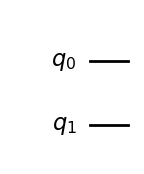

In [4]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

qc = QuantumCircuit(2)  # a circuit with 2 qubits, numbered 0 and 1
qc.draw("mpl")          # draw the (still empty) circuit

## 3. Put a Hadamard gate on qubit 0

The Hadamard gate $$H$$ puts a qubit into an equal superposition:

$$H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$$

Note on ordering: Qiskit writes qubit 0 on the right, so a state like $$|01\rangle$$ means qubit 1 is in $$|0\rangle$$ and qubit 0 is in $$|1\rangle$$.

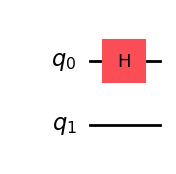

In [5]:
qc.h(0)          # Hadamard on qubit 0
qc.draw("mpl")

In [6]:
# Result: look at the quantum state (only possible on a simulator!)
Statevector(qc).draw("latex")

<IPython.core.display.Latex object>

We get $$\frac{|00\rangle + |01\rangle}{\sqrt{2}}$$: qubit 0 is in superposition, qubit 1 is still $$|0\rangle$$.

## 4. Add a CNOT gate to create entanglement

The CNOT (controlled NOT) gate flips the target qubit (here qubit 1) only if the control qubit (here qubit 0) is $$|1\rangle$$. Applied to our superposition it gives the Bell state

$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$

The two qubits are now entangled: neither has a definite value on its own, but they always agree. Measure one and you immediately know the other.

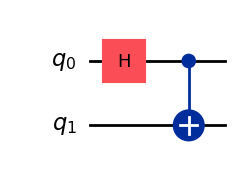

In [7]:
qc.cx(0, 1)      # CNOT: control = qubit 0, target = qubit 1
qc.draw("mpl")

In [9]:
Statevector(qc).draw("latex")  # should show (|00> + |11>)/sqrt(2)

<IPython.core.display.Latex object>

## 5. Run it on a virtual quantum computer

A real quantum computer only gives us measurement results, so we add measurements to every qubit. We first run on a simulator, a program on your own computer that behaves like a perfect (noise free) quantum computer.

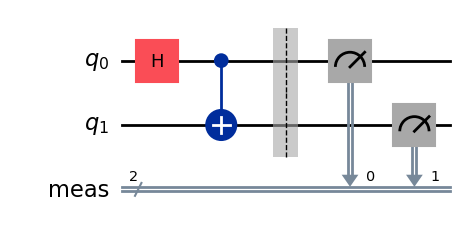

In [10]:
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

qc_measured = qc.measure_all(inplace=False)  # copy of the circuit with measurements added
qc_measured.draw("mpl")

{'11': 508, '00': 492}


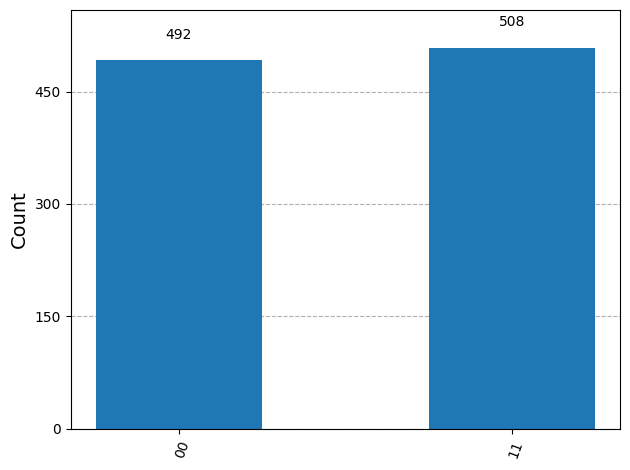

In [11]:
sampler = StatevectorSampler()                 # the virtual quantum computer
job = sampler.run([qc_measured], shots=1000)   # run the circuit 1000 times
counts = job.result()[0].data.meas.get_counts()

print(counts)
plot_histogram(counts)

## 6. What are shots?

Measurement collapses the state: each run gives just one answer, either `00` or `11`, chosen at random. One run alone cannot tell us we had a superposition.

The quantum state gives the probabilities. For our Bell state

$$P(00) = \left|\frac{1}{\sqrt{2}}\right|^2 = 0.5, \quad P(11) = 0.5, \quad P(01) = P(10) = 0$$

So we repeat the whole circuit many times. Each repetition is called a shot. With enough shots the counts approach these probabilities and reveal the state we prepared. Try it below.

In [12]:
# Same circuit, different numbers of shots
for shots in [1, 10, 100, 1000]:
    counts = sampler.run([qc_measured], shots=shots).result()[0].data.meas.get_counts()
    print(shots, "shots:", counts)

1 shots: {'00': 1}
10 shots: {'11': 4, '00': 6}
100 shots: {'00': 44, '11': 56}
1000 shots: {'00': 497, '11': 503}


Notice that `01` and `10` never appear: the qubits are always correlated. That is the signature of entanglement.

## 7. Submit it to a real quantum computer

Before the first run:
1. Create a free account on [IBM Quantum Platform](https://quantum.cloud.ibm.com/).
2. Copy your API key from the dashboard.
3. Copy your instance CRN (an ID for your account's compute instance) from the [Instances](https://quantum.cloud.ibm.com/instances) page.

Then run the next cell once to save your credentials on your computer (do not share notebooks with your key in them).

In [13]:
from qiskit_ibm_runtime import QiskitRuntimeService

# Run ONCE, then comment it out again
# QiskitRuntimeService.save_account(
#     token="<your-api-key>",
#     instance="<your-CRN>",
#     overwrite=True,
# )

Real hardware only understands its own set of gates and only some qubit pairs are connected. Transpiling rewrites our circuit into that form. We then use the Sampler on the real device. Jobs wait in a queue, so this can take a few minutes.

In [ ]:
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit.transpiler import generate_preset_pass_manager

service = QiskitRuntimeService()                                 # log in with saved credentials
backend = service.least_busy(simulator=False, operational=True)  # pick the least busy real device
print("Running on:", backend.name)

pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc_measured)       # transpile for this device

sampler_real = Sampler(mode=backend)
job_real = sampler_real.run([isa_circuit], shots=1000)
print("Job ID:", job_real.job_id())     # keep this to find your job later

In [ ]:
# Wait for the result and plot it
counts_real = job_real.result()[0].data.meas.get_counts()
print(counts_real)
plot_histogram(counts_real)

On real hardware you will see mostly `00` and `11`, plus a few `01` and `10`. Those extra results come from noise: real qubits are imperfect and lose their quantum state over time. Comparing the simulator and the hardware histograms is a direct way to see how good today's quantum computers are.

## Further resources

- [IBM Quantum Learning](https://quantum.cloud.ibm.com/learning/en): free courses from the basics upward
- [Hello world guide](https://quantum.cloud.ibm.com/docs/en/guides/hello-world): IBM's version of this example
- [Qiskit on GitHub](https://github.com/Qiskit/qiskit): source code and installation notes
- [Qiskit Fall Fest 2026 resources](https://github.com/ZohaibCodez/qiskit-fall-fest-2026/blob/main/content/resources.json)